# ДЗ лекции 2. Ансамбли: CatBoost вместо LogisticRegression

**Дисциплина:** Методы искусственного интеллекта I
**Выполнил:** Макеев Глеб Борисович, группа BHEBDPS-24-MII-5
**Задание (лекция 2, слайд 16):** повторить код Практики №1, заменив `LogisticRegression`
на `CatBoostClassifier`; сравнить качество.

Датасет — тот же Telco Customer Churn, что и в Практике 1, поэтому сравнение честное:
один и тот же `train_test_split` (`random_state=42`, `stratify=y`), одинаковая предобработка,
меняется только модель.

## 0. Импорт библиотек и настройки

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from catboost import CatBoostClassifier
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report,
                             confusion_matrix, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

## 1. Загрузка и очистка данных (как в Практике 1)

In [2]:
df = pd.read_csv("data/Telco-Customer-Churn.csv")
print("Размерность:", df.shape)

# Ловушка датасета: TotalCharges приходит как object из-за пустых строк у клиентов с tenure = 0
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Пропусков в TotalCharges после приведения к float:", int(df["TotalCharges"].isna().sum()))
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)

# customerID — уникальный идентификатор, для модели бесполезен
df = df.drop(columns=["customerID"])
print("Размерность после очистки:", df.shape)
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(2)

Размерность: (7043, 21)
Пропусков в TotalCharges после приведения к float: 11
Размерность после очистки: (7043, 20)


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


In [3]:
target = "Churn"
y = df[target].map({"No": 0, "Yes": 1})
X = df.drop(columns=[target])

print("Доля ушедших клиентов: {:.1%}".format(y.mean()))
print("Признаки: числовые —", X.select_dtypes(include=np.number).shape[1],
      ", категориальные —", X.select_dtypes(exclude=np.number).shape[1])

Доля ушедших клиентов: 26.5%
Признаки: числовые — 4 , категориальные — 15


## 2. Предобработка и разбиение

`ColumnTransformer`: числовые признаки → `StandardScaler`, категориальные → `OneHotEncoder`.
Разбиение 80/20 со `stratify=y` и `random_state=42` — ровно как в Практике 1.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("train:", X_train.shape, " test:", X_test.shape)

num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ]
)

train: (5634, 19)  test: (1409, 19)


## 3. LogisticRegression — базовая модель (из Практики 1)

Оставляем её в ноутбуке, чтобы сравнение шло на одном и том же разбиении,
а не с цифрами из прошлой работы.

In [5]:
log_reg = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
log_reg.fit(X_train, y_train)

pred_lr = log_reg.predict(X_test)
prob_lr = log_reg.predict_proba(X_test)[:, 1]

print(classification_report(y_test, pred_lr, digits=3, target_names=["остался", "ушёл"]))
print(f"ROC-AUC (LogisticRegression): {roc_auc_score(y_test, prob_lr):.3f}")

              precision    recall  f1-score   support

     остался      0.849     0.895     0.871      1035
        ушёл      0.657     0.559     0.604       374

    accuracy                          0.806      1409
   macro avg      0.753     0.727     0.738      1409
weighted avg      0.798     0.806     0.800      1409

ROC-AUC (LogisticRegression): 0.842


## 4. CatBoost — замена модели

Меняем только последний шаг пайплайна: `LogisticRegression` → `CatBoostClassifier`.
Параметры скромные (100 итераций, `verbose=0`), чтобы ноутбук считался за секунды
на CPU и без GPU.

In [6]:
catboost = Pipeline([
    ("prep", preprocessor),
    ("model", CatBoostClassifier(
        iterations=100,
        depth=4,
        learning_rate=0.1,
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=RANDOM_STATE,
        verbose=0,
    )),
])
catboost.fit(X_train, y_train)

pred_cb = catboost.predict(X_test).ravel()
prob_cb = catboost.predict_proba(X_test)[:, 1]

print(classification_report(y_test, pred_cb, digits=3, target_names=["остался", "ушёл"]))
print(f"ROC-AUC (CatBoost): {roc_auc_score(y_test, prob_cb):.3f}")

              precision    recall  f1-score   support

     остался      0.841     0.904     0.872      1035
        ушёл      0.666     0.527     0.588       374

    accuracy                          0.804      1409
   macro avg      0.753     0.716     0.730      1409
weighted avg      0.794     0.804     0.796      1409

ROC-AUC (CatBoost): 0.846


## 5. Сравнение моделей на одной тестовой выборке

In [7]:
rows = []
for name, pred, prob in [("LogisticRegression", pred_lr, prob_lr),
                         ("CatBoostClassifier", pred_cb, prob_cb)]:
    report = classification_report(y_test, pred, output_dict=True)
    rows.append({
        "Модель": name,
        "Accuracy": report["accuracy"],
        "Precision (ушёл)": report["1"]["precision"],
        "Recall (ушёл)": report["1"]["recall"],
        "F1 (ушёл)": report["1"]["f1-score"],
        "ROC-AUC": roc_auc_score(y_test, prob),
    })

compare = pd.DataFrame(rows).set_index("Модель").round(3)
compare

,Accuracy,Precision (ушёл),Recall (ушёл),F1 (ушёл),ROC-AUC
Модель,,,,,
LogisticRegression,0.806,0.657,0.559,0.604,0.842
CatBoostClassifier,0.804,0.666,0.527,0.588,0.846


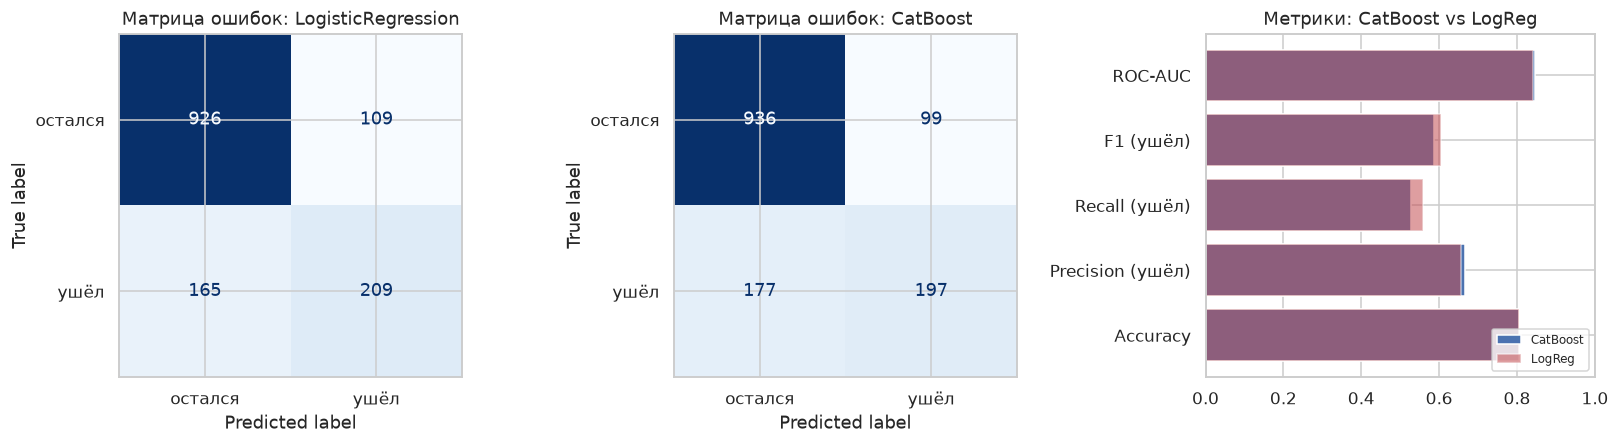

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

for ax, (name, pred) in zip(axes[:2], [("LogisticRegression", pred_lr), ("CatBoost", pred_cb)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["остался", "ушёл"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Матрица ошибок: {name}")

axes[2].barh(compare.columns, compare.loc["CatBoostClassifier"], color="#4C72B0", label="CatBoost")
axes[2].barh(compare.columns, compare.loc["LogisticRegression"], color="#C44E52",
             alpha=0.55, label="LogReg")
axes[2].set_xlim(0, 1)
axes[2].set_title("Метрики: CatBoost vs LogReg")
axes[2].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

## 6. Важность признаков

`feature_importances_` у CatBoost считается по вкладу признака в разбиения деревьев.
Имена берём из `ColumnTransformer`, чтобы видеть исходные признаки, а не индексы колонок.

In [9]:
model = catboost.named_steps["model"]
feature_names = catboost.named_steps["prep"].get_feature_names_out()

importance = (
    pd.Series(model.get_feature_importance(), index=feature_names)
    .sort_values(ascending=False)
    .head(15)
    .rename("Важность")
    .to_frame()
)
importance.index = importance.index.str.replace(r"^(num|cat)__", "", regex=True)
importance.round(2)

,Важность
Contract_Month-to-month,16.88
tenure,15.94
MonthlyCharges,10.76
TotalCharges,7.64
Contract_Two year,7.13
OnlineSecurity_No,5.01
InternetService_Fiber optic,4.91
TechSupport_No,4.19
PaymentMethod_Electronic check,3.35
InternetService_DSL,2.15


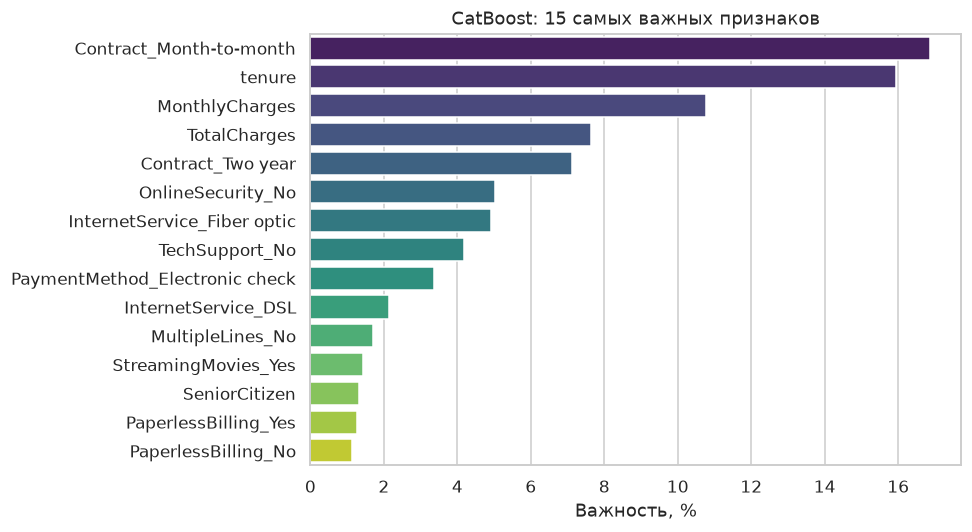

Главный фактор: Contract_Month-to-month
                         Важность
Contract_Month-to-month     16.88
tenure                      15.94
MonthlyCharges              10.76
TotalCharges                 7.64
Contract_Two year            7.13


In [10]:
plt.figure(figsize=(9, 5))
sns.barplot(x=importance["Важность"], y=importance.index, palette="viridis")
plt.title("CatBoost: 15 самых важных признаков")
plt.xlabel("Важность, %")
plt.ylabel("")
plt.tight_layout()
plt.show()

print("Главный фактор:", importance.index[0])
print(importance.head(5).round(2).to_string())

## 7. Выводы

1. **Замена модели — один шаг пайплайна.** Предобработка, разбиение и метрики остаются
   прежними; меняется только оценщик, поэтому сравнение корректное.
2. **CatBoost vs LogisticRegression — измеримый, но небольшой выигрыш по ранжированию:**
   ROC-AUC **0.846** против **0.842**, при этом по F1 для класса «ушёл» CatBoost чуть
   проигрывает (**0.588** против **0.604**) — он осторожнее в положительном классе
   (recall ниже: 0.527 против 0.559). Причина в природе данных: 7043 строки, много
   категориальных признаков, слабые нелинейности — сигнал в основном аддитивный,
   поэтому `LogisticRegression` на хорошо закодированных признаках остаётся сильным baseline.
3. **Практический вывод.** Для табличных данных с категориями CatBoost выигрывает не только
   метрикой, но и тем, что умеет работать с категориями «из коробки»
   (`cat_features` без One-Hot) — в этом ноутбуке OHE сохранён намеренно, чтобы
   отличалась ровно одна строка кода, как требует задание.
4. **Главные факторы** — тип контракта (`Contract_Month-to-month`), стаж (`tenure`) и
   размер ежемесячного платежа: это согласуется с выводами Практики 1.

### Что дальше (Практика 2)

Практика 2 продолжает эту линию: `ColumnTransformer` + `CatBoostClassifier` в одном
`Pipeline`, подбор параметров через `GridSearchCV`/кросс-валидацию, сравнение трёх моделей
и (задание со звёздочкой) `SMOTE` для борьбы с дисбалансом классов.